### Katalog Danych

In [1]:
import os

from BayesianNetwork.network import MyNetworkClass

REPO = "k12"

data_path = os.path.join('..', 'data', 'zestawy', REPO)
files = os.listdir(data_path)

files

/home/kendama/Projects/University_Classes/SEM_5/IFM_konwoledge_enginnering/.venv/lib/python3.13/site-packages/pgmpy/estimators/__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


['zapytania.txt', 'dane.csv', 'test.csv', 'ograniczenia.txt', 'opis.json']

In [2]:
from BayesianNetwork.parsing.data_parsing import parse_data
from BayesianNetwork.parsing.description_parsing import description_parser

graph = description_parser(os.path.join(data_path, 'opis.json'))
variables = graph.variables_dict

train_data = parse_data(os.path.join(data_path, 'dane.csv'), variables, is_train_data=True)
test_data = parse_data(os.path.join(data_path, 'test.csv'), variables, is_train_data=False)


/tmp/ipykernel_71743/2077792439.py:7: UserWarning: Train data contains 4740 nans
  train_data = parse_data(os.path.join(data_path, 'dane.csv'), variables, is_train_data=True)


## Funkcje i zmienne pomocnicze

In [14]:
from typing import List, Tuple
from matplotlib import pyplot as plt
import networkx as nx

def draw_network(nodes: List[str], edges: List[Tuple[str, str]]):
    """
    Draws a directed graph given a list of nodes and a list of edges with arrows.

    :param nodes: List of strings representing node names.
    :param edges: List of tuples (str, str) representing directed connections (from, to).
    """
    # Create a directed graph object
    G = nx.DiGraph()

    # Add nodes and edges to the graph
    G.add_nodes_from(nodes)
    G.add_edges_from(edges)

    # Set up the plot layout and appearance
    plt.figure(figsize=(8, 6))
    pos = nx.spring_layout(G)  # Computes a layout using a force-directed algorithm

    # Draw nodes
    nx.draw_networkx_nodes(
        G, pos,
        node_color='lightblue',
        node_size=800,
        edgecolors='black',
        linewidths=1.5
    )

    # Draw node labels
    nx.draw_networkx_labels(G, pos, font_size=12, font_weight='bold')

    # Draw directed edges with arrows
    nx.draw_networkx_edges(
        G, pos,
        node_size=800,
        edge_color='gray',
        arrowstyle='-|>',
        arrowsize=20,
        width=1.5,
        connectionstyle='arc3,rad=0.1' # Slightly curves edges to handle bidirectional links neatly
    )

    plt.title("Directed Network Graph", fontsize=14, fontweight='bold')
    plt.axis('off')  # Hide the axes
    plt.show()

def score_model(model):
    global test_data

    p, log, zeros = model.score(test_data)

    print(f"Średni Log Prawdopodobieństwa: {log}\n"
          f"Średnie Prawdopodobieństwo: {p}\n"
          f"Licznik zer: {zeros}")

nodes = list(graph.variables_dict.keys())

# 0. Graf Ekspercki

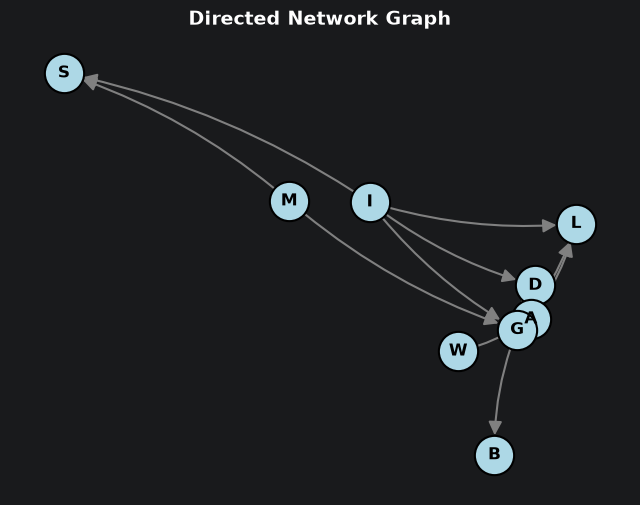

[('A', 'L'), ('D', 'A'), ('D', 'G'), ('G', 'B'), ('G', 'L'), ('I', 'D'), ('I', 'G'), ('I', 'L'), ('I', 'S'), ('M', 'G'), ('M', 'S'), ('W', 'A')]


In [4]:
draw_network(nodes, graph.exper_edges)
print(graph.exper_edges)

In [15]:
from BayesianNetwork.network.MyNetworkClass import MyNetworkClass

expr_model = MyNetworkClass.build_from_expert_graph(graph, train_data)
score_model(expr_model)

Średni Log Prawdopodobieństwa: -4.570395747101035
Średnie Prawdopodobieństwo: 0.025707830293269836
Licznik zer: 6


# 1. Bez Wiedzy Eksperckiej

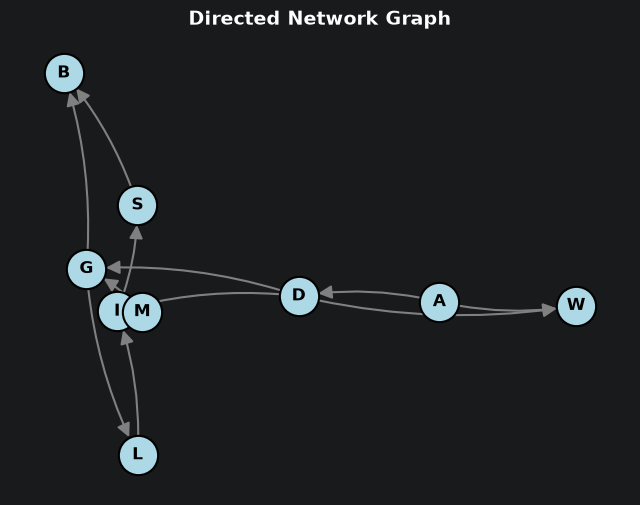

['D', 'I', 'M', 'W', 'A', 'G', 'S', 'L', 'B']
[('D', 'I'), ('D', 'G'), ('D', 'W'), ('I', 'S'), ('M', 'G'), ('A', 'D'), ('A', 'W'), ('G', 'L'), ('G', 'B'), ('S', 'B'), ('L', 'I')]
BIC: -2090.626095483015


In [6]:
from BayesianNetwork.network.MyNetworkClass import MyNetworkClass

dag, bic = MyNetworkClass.learn_structure_HC(train_data)

edges = list(dag.edges)
nodes = list(dag.nodes)
draw_network(nodes, edges)

print(nodes)
print(edges)
print(f"BIC: {bic}")

In [16]:
model_1 = MyNetworkClass.build_network(train_data, graph.variables_dict)
score_model(model_1)

Średni Log Prawdopodobieństwa: -4.603517918774296
Średnie Prawdopodobieństwo: 0.025387535975796235
Licznik zer: 0


# 2. Wiedza Ekspercka
Warstwy, Krawędzie Wymagane i Zabronione

In [8]:
from pgmpy.causal_discovery import ExpertKnowledge

expert = ExpertKnowledge(
    required_edges=graph.required_edges,
    forbidden_edges=graph.forbidden_edges,
    temporal_order=graph.tiers
)

expert

Expert Knowledge: 4 required edges, 4 forbidden edges, temporal order on 9 nodes, and 0 search space edges

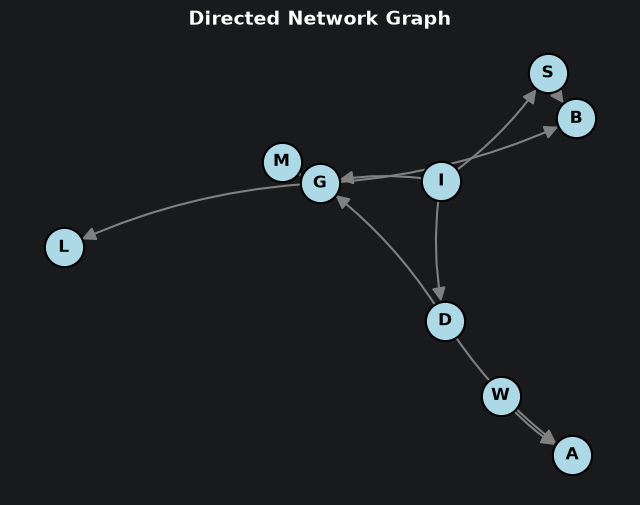

['D', 'I', 'M', 'W', 'A', 'G', 'S', 'L', 'B']
[('D', 'G'), ('D', 'A'), ('I', 'S'), ('I', 'G'), ('I', 'D'), ('M', 'G'), ('W', 'A'), ('G', 'L'), ('G', 'B'), ('S', 'B')]
BIC: -2088.8992860986614


In [9]:
dag, bic = MyNetworkClass.learn_structure_HC(train_data, expert)
edges = list(dag.edges)
nodes = list(dag.nodes)
draw_network(nodes, edges)

print(nodes)
print(edges)
print(f"BIC: {bic}")

In [17]:
model_2 = MyNetworkClass.build_network(train_data, graph.variables_dict, expert)
score_model(model_2)

Średni Log Prawdopodobieństwa: -4.560219355979076
Średnie Prawdopodobieństwo: 0.025572778009036432
Licznik zer: 3


# 3. Imputacja danych i pełny graf ekspercki

## Imputacja danych Modelem zbudowanym na podstawie grafu eksperckiego

In [10]:
import numpy as np
import pandas as pd
from pgmpy.inference import VariableElimination
from pgmpy.models import DiscreteBayesianNetwork

from BayesianNetwork.models.data import Data, DataPurpose
from BayesianNetwork.algorithms.em_cdps_estimation import learn_cpds_em

def impute_with_em(df: pd.DataFrame, parents: dict, max_iter:int = 1000) -> pd.DataFrame:

    cpds, _ = learn_cpds_em(Data(data_purpose=DataPurpose.Train, data_frame=df), parents=parents, max_iter=max_iter)

    model = DiscreteBayesianNetwork()
    model.add_nodes_from(df.columns)
    model.add_edges_from(
        (parent, child)
        for child, child_parents in parents.items()
        for parent in child_parents
    )
    model.add_cpds(*cpds)
    model.check_model()

    infer = VariableElimination(model)
    result = df.copy()

    for row_idx, row in df.iterrows():
        missing = [col for col in df.columns if pd.isna(row[col])]
        if not missing:
            continue

        # Use the original observed values as evidence, not values filled earlier.
        evidence = {
            col: row[col]
            for col in df.columns
            if pd.notna(row[col])
        }

        for col in missing:
            posterior = infer.query(
                variables=[col],
                evidence=evidence,
                show_progress=False,
            )
            states = posterior.state_names[col]
            result.at[row_idx, col] = states[int(np.argmax(posterior.values))]

    return result

In [11]:
expert_net = MyNetworkClass.build_from_expert_graph(graph, train_data)

parents = {var : [] for var in variables.keys()}
for parent, child in graph.exper_edges:
    parents[child].append(parent)

imputed_data = Data(
    data_purpose=DataPurpose.Train,
    data_frame=impute_with_em(train_data.data_frame, parents)
)

imputed_data.data_frame

,D,I,M,W,A,G,S,L,B
0,Easy,Dumb,Low,No,High,B,Bad,Bad,No
1,Easy,Dumb,High,No,Medium,A,Bad,Good,Yes
2,Hard,Dumb,Low,No,Low,C,Bad,Bad,No
3,Easy,Dumb,High,No,High,A,Bad,Good,Yes
4,Hard,Dumb,High,No,Medium,C,Bad,Bad,No
...,...,...,...,...,...,...,...,...,...
2995,Easy,Dumb,Low,Yes,Medium,C,Bad,Bad,No
2996,Easy,Dumb,High,No,High,A,Bad,Good,Yes
2997,Easy,Dumb,High,Yes,Medium,A,Bad,Good,Yes
2998,Hard,Dumb,High,No,Low,C,Bad,Bad,No


## Struktura na Imputowanych danych

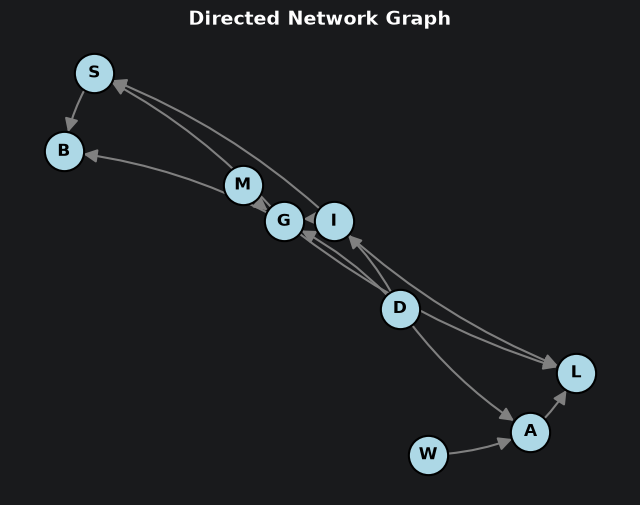

['D', 'I', 'M', 'W', 'A', 'G', 'S', 'L', 'B']
[('D', 'G'), ('D', 'A'), ('D', 'I'), ('I', 'S'), ('I', 'G'), ('I', 'L'), ('M', 'G'), ('W', 'A'), ('A', 'L'), ('G', 'L'), ('G', 'B'), ('G', 'S'), ('S', 'B')]
BIC: -13310.112074208788


In [12]:
dag, bic = MyNetworkClass.learn_structure_HC(imputed_data, expert)
edges = list(dag.edges)
nodes = list(dag.nodes)
draw_network(nodes, edges)

print(nodes)
print(edges)
print(f"BIC: {bic}")


In [18]:
model_3 = MyNetworkClass.build_network(imputed_data, graph.variables_dict, expert)
score_model(model_3)

Średni Log Prawdopodobieństwa: -4.556105407455615
Średnie Prawdopodobieństwo: 0.0296950893837607
Licznik zer: 4
